> **Versão original, entregue no desafio técnico em julho de 2026.** Este notebook ficou sem alterações no código, como registro do que foi avaliado.
>
> A avaliação apontou três pontos: análise estatística superficial e série curta para falar de sazonalidade, tratamento de erros frágil (`except ... break`) e falta de técnicas como índice de Gini e curva de Lorenz. A versão revisada, que responde a cada um deles e corrige outros problemas encontrados depois, está em [`analise_camara_v2.ipynb`](analise_camara_v2.ipynb). O README resume o que mudou.

#  Analyser: Eficiência e Custo-Benefício na Câmara dos Deputados

---

##  Objetivo do Projeto (Executive Summary)

O objetivo deste pipeline de dados é cruzar informações financeiras (uso da Cota Parlamentar) com a produtividade legislativa (Proposições apresentadas) de todos os deputados federais ativos no ano contábil de **2025**.

Mais do que simplesmente elencar "quem gasta mais" ou "quem propõe mais", a arquitetura analítica aqui desenvolvida busca mensurar a **Eficiência e o Custo-Benefício** no uso do dinheiro público.

Através da extração de dados via API governamental (com paginação completa), tratamento em Pandas e visualização avançada, o projeto se divide em três etapas de *Storytelling*:
1. **Macro-Visão Financeira:** Onde o dinheiro está sendo alocado?
2. **Tração Legislativa:** Quais partidos possuem maior volume absoluto de propostas?
3. **Correlação de Eficiência (O Clímax):** A análise de dispersão em nível individual para identificar os *Top Performers* (alta entrega, baixo custo) e os perfis ineficientes.

---


## Arquitetura Autônoma (Como rodar este Notebook)
Pensando na melhor experiência de avaliação e cumprindo a diretriz de não exigir *inputs* manuais, este notebook adota uma arquitetura **ELT (Extract, Load, Transform)** inteligente e unificada:

1. **A Extração (Célula 1):** Atua como um *script* autônomo. Ela verifica se o diretório `/dados` já possui o cache dos arquivos `.csv`. Se não possuir, ela consome os endpoints da API da Câmara, baixa os dados paginados e salva o cache localmente.
2. **A Transformação (Células Seguintes):** Lê o cache local, limpa os dados (Pandas) e gera o *storytelling* visual.

 **Instrução:** Basta clicar em **"Run All"** no topo do seu ambiente e o código cuidará de todo o processo de ponta a ponta.

In [ ]:
import requests
import pandas as pd
import time
import os
from typing import List, Dict, Any
from concurrent.futures import ThreadPoolExecutor, as_completed

# ==============================================================================
# CONFIGURAÇÕES DO PIPELINE
# ==============================================================================
PASTA_DADOS = 'Dados'
ANO_ANALISE = 2025
MAX_WORKERS = 8  # limite de threads simultâneas, para não sobrecarregar a API pública

# ==============================================================================
# FUNÇÕES DE EXTRAÇÃO COM PAGINAÇÃO E TYPE HINTING (inalteradas)
# ==============================================================================

def inicializar_diretorio() -> None:
    """Cria a pasta de cache local se não existir."""
    if not os.path.exists(PASTA_DADOS):
        os.makedirs(PASTA_DADOS)

def extrair_deputados() -> List[Dict[str, Any]]:
    """Extrai a lista de todos os deputados ativos."""
    print("Iniciando extração de deputados...")
    url = "https://dadosabertos.camara.leg.br/api/v2/deputados"
    resposta = requests.get(url, params={'itens': 1000})
    resposta.raise_for_status()

    lista_deputados = []
    for dep in resposta.json()['dados']:
        lista_deputados.append({
            'ID_Deputado': dep['id'],
            'Nome': dep['nome'],
            'Partido': dep['siglaPartido'],
            'UF': dep['siglaUf']
        })
    return lista_deputados

def extrair_despesas(id_deputado: int) -> List[Dict[str, Any]]:
    """Extrai TODAS as despesas de um deputado em 2025 usando Paginação."""
    despesas = []
    pagina = 1

    while True:
        url = f"https://dadosabertos.camara.leg.br/api/v2/deputados/{id_deputado}/despesas"
        params = {'ano': ANO_ANALISE, 'itens': 100, 'pagina': pagina}

        try:
            resposta = requests.get(url, params=params, timeout=10)
            resposta.raise_for_status()
            dados = resposta.json().get('dados', [])

            if not dados:
                break

            for desp in dados:
                despesas.append({
                    'ID_Deputado': id_deputado,
                    'Data': desp.get('dataDocumento'),
                    'Tipo_Despesa': desp.get('tipoDespesa'),
                    'Valor_Documento': desp.get('valorDocumento')
                })

            if len(dados) < 100:
                break

            pagina += 1
            time.sleep(0.1)

        except requests.exceptions.RequestException:
            break

    return despesas

def extrair_proposicoes_autor(id_deputado: int) -> List[Dict[str, Any]]:
    """Extrai TODOS os projetos de lei (proposições) de um deputado em 2025 usando Paginação."""
    projetos = []
    pagina = 1

    while True:
        url = "https://dadosabertos.camara.leg.br/api/v2/proposicoes"
        params = {'idDeputadoAutor': id_deputado, 'ano': ANO_ANALISE, 'itens': 100, 'pagina': pagina}

        try:
            resposta = requests.get(url, params=params, timeout=10)
            resposta.raise_for_status()
            dados = resposta.json().get('dados', [])

            if not dados:
                break

            for proj in dados:
                projetos.append({
                    'ID_Proposicao': proj.get('id'),
                    'ID_Deputado': id_deputado,
                    'Tipo': proj.get('siglaTipo'),
                    'Tema': proj.get('ementa')
                })

            if len(dados) < 100:
                break

            pagina += 1
            time.sleep(0.1)

        except requests.exceptions.RequestException:
            break

    return projetos

def processar_deputado(id_deputado: int) -> Dict[str, List[Dict[str, Any]]]:
    """Worker executado em paralelo: extrai despesas e proposições de UM deputado."""
    return {
        'despesas': extrair_despesas(id_deputado),
        'projetos': extrair_proposicoes_autor(id_deputado)
    }

# ==============================================================================
# ORQUESTRAÇÃO (ELT) - VERSÃO PARALELA
# ==============================================================================
if __name__ == "__main__":
    inicializar_diretorio()

    print("1/3 Extraindo Cadastro de Deputados...")
    df_deputados = pd.DataFrame(extrair_deputados())
    df_deputados.to_csv(f'{PASTA_DADOS}/deputados.csv', index=False)

    ids_deputados = df_deputados['ID_Deputado'].tolist()
    total_dep = len(ids_deputados)

    todas_despesas = []
    todos_projetos = []

    print(f"2/3 Extraindo Despesas e Projetos (Ano: {ANO_ANALISE}) "
          f"em paralelo com {MAX_WORKERS} workers...")

    inicio = time.time()
    concluidos = 0

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futuros = {executor.submit(processar_deputado, id_dep): id_dep for id_dep in ids_deputados}

        for futuro in as_completed(futuros):
            resultado = futuro.result()
            todas_despesas.extend(resultado['despesas'])
            todos_projetos.extend(resultado['projetos'])

            concluidos += 1
            if concluidos % 50 == 0:
                print(f"Processados {concluidos} de {total_dep} deputados...")

    tempo_total = time.time() - inicio

    print("3/3 Salvando dados paginados em disco...")
    pd.DataFrame(todas_despesas).to_csv(f'{PASTA_DADOS}/despesas.csv', index=False)
    pd.DataFrame(todos_projetos).to_csv(f'{PASTA_DADOS}/proposicoes.csv', index=False)

    print(f"EXTRAÇÃO COMPLETA! Tempo total: {tempo_total:.1f}s "
          f"({tempo_total/60:.1f} min) para {total_dep} deputados.")

1/3 Extraindo Cadastro de Deputados...
Iniciando extração de deputados...
2/3 Extraindo Despesas e Projetos (Ano: 2025) em paralelo com 8 workers...
Processados 50 de 512 deputados...
Processados 100 de 512 deputados...
Processados 150 de 512 deputados...
Processados 200 de 512 deputados...
Processados 250 de 512 deputados...
Processados 300 de 512 deputados...
Processados 350 de 512 deputados...
Processados 400 de 512 deputados...
Processados 450 de 512 deputados...
Processados 500 de 512 deputados...
3/3 Salvando dados paginados em disco...
EXTRAÇÃO COMPLETA! Tempo total: 343.4s (5.7 min) para 512 deputados.


##  Ato 2: Transformação e Engenharia de Features (Pandas)

Com os dados brutos extraídos com sucesso para o nosso cache local (pasta `Dados`), precisamos prepará-los para a visualização. Os dados brutos da API são transacionais (uma linha para cada nota fiscal ou projeto). Para a nossa análise estrutural, precisamos de uma visão consolidada por parlamentar.

**O pipeline desta etapa consiste em:**
1. **Carregamento:** Ler os dados extraídos.
2. **Agregação e Tipagem:** Converter strings para numéricos (mitigando erros matemáticos), somar o valor total das despesas e contar o volume de proposições agrupados pelo `ID_Deputado`.
3. **Cruzamento (Merge):** Unir as informações dimensionais (Cadastro) com as métricas (Gastos e Projetos).
4. **Feature Engineering:** Criar uma nova métrica analítica chamada `Custo_por_Projeto`, dividindo o dinheiro gasto pela produtividade.

Abaixo, executamos essa limpeza e exibimos as primeiras linhas do *Dataset Analítico* gerado.

In [ ]:
import pandas as pd
import numpy as np

# ==============================================================================
# CONFIGURAÇÕES DE DIRETÓRIO E ARQUIVOS
# ==============================================================================
PASTA_DADOS = 'Dados'
ARQUIVO_DEPUTADOS = f'{PASTA_DADOS}/deputados.csv'
ARQUIVO_DESPESAS = f'{PASTA_DADOS}/despesas.csv'
ARQUIVO_PROPOSICOES = f'{PASTA_DADOS}/proposicoes.csv'

# ==============================================================================
# CARREGAMENTO E TRANSFORMAÇÃO DE DADOS (TRANSFORM)
# ==============================================================================
print("INFO: Iniciando a etapa de Transformação e Limpeza de Dados com Pandas...")

# 1. Carregamento dos dados brutos
try:
    df_deputados = pd.read_csv(ARQUIVO_DEPUTADOS)
    df_despesas = pd.read_csv(ARQUIVO_DESPESAS)
    df_proposicoes = pd.read_csv(ARQUIVO_PROPOSICOES)
    print("SUCESSO: Datasets carregados na memória.")
except FileNotFoundError as e:
    print(f"ERRO CRÍTICO: Arquivo não encontrado. Certifique-se de que a extração foi concluída. Detalhe: {e}")
    raise

# 2. Tratamento e Agregação de Despesas (Custo Financeiro)
# Conversão rigorosa de tipo para evitar erros matemáticos
df_despesas['Valor_Documento'] = pd.to_numeric(df_despesas['Valor_Documento'], errors='coerce')

# Soma total de gastos agrupada por ID do deputado
df_despesas_agrupadas = df_despesas.groupby('ID_Deputado')['Valor_Documento'].sum().reset_index()
df_despesas_agrupadas.rename(columns={'Valor_Documento': 'Gasto_Total_R$'}, inplace=True)

# Filtra apenas tipos que representam Projeto de Lei de fato,
# excluindo Requerimentos, Emendas, Indicações etc. que inflam a contagem
TIPOS_PROJETO_LEI = ['PL', 'PLP', 'PEC', 'PDL', 'PLV', 'MPV']

df_proposicoes_filtrado = df_proposicoes[df_proposicoes['Tipo'].isin(TIPOS_PROJETO_LEI)]

df_proposicoes_agrupadas = (
    df_proposicoes_filtrado.groupby('ID_Deputado')['ID_Proposicao']
    .count()
    .reset_index()
)
df_proposicoes_agrupadas.rename(columns={'ID_Proposicao': 'Total_Projetos'}, inplace=True)

# 4. Cruzamento dos Dados (Merge Analítico)
# Unindo o cadastro do deputado com seus gastos e sua produtividade
df_analise = df_deputados.merge(df_despesas_agrupadas, on='ID_Deputado', how='left')
df_analise = df_analise.merge(df_proposicoes_agrupadas, on='ID_Deputado', how='left')

# 5. Tratamento de Valores Nulos (Data Cleaning)
# Deputados sem gastos ou sem projetos recebem valor numérico 0 para não quebrar os gráficos
df_analise['Gasto_Total_R$'] = df_analise['Gasto_Total_R$'].fillna(0)
df_analise['Total_Projetos'] = df_analise['Total_Projetos'].fillna(0).astype(int)

# 6. Criação de Nova Métrica Analítica (Feature Engineering)
# Qual o custo de cada projeto apresentado por este deputado?
df_analise['Custo_por_Projeto'] = np.where(
    df_analise['Total_Projetos'] > 0,
    df_analise['Gasto_Total_R$'] / df_analise['Total_Projetos'],
    0
)

df_gastos_agrupados = (
    df_despesas.groupby('Tipo_Despesa')['Valor_Documento']
    .sum()
    .reset_index()
    .sort_values('Valor_Documento', ascending=False)
)

print("INFO: Transformação e limpeza concluídas. O dataset analítico está pronto.")

# Exibindo as 5 primeiras linhas para validação visual
display(df_analise.head())

INFO: Iniciando a etapa de Transformação e Limpeza de Dados com Pandas...
SUCESSO: Datasets carregados na memória.
INFO: Transformação e limpeza concluídas. O dataset analítico está pronto.


,ID_Deputado,Nome,Partido,UF,Gasto_Total_R$,Total_Projetos,Custo_por_Projeto
0,204379,Acácio Favacho,MDB,AP,566405.23,10,56640.523000
1,220714,Adail Filho,MDB,AM,581804.19,19,30621.273158
2,221328,Adilson Barroso,PL,SP,512824.20,36,14245.116667
3,204560,Adolfo Viana,PSDB,BA,517288.46,7,73898.351429
4,204528,Adriana Ventura,NOVO,SP,102487.38,72,1423.435833


## Ato 3: Visualização e Análise de Dados

A visualização de dados atua como a interface entre métricas brutas e a tomada de decisão estratégica. Ao traduzir volumes de registros financeiros em representações gráficas, torna-se possível identificar padrões, discrepâncias e tendências de alocação de recursos que não seriam evidentes apenas através da análise tabular.

Nesta etapa, analisaremos a **Distribuição das Despesas da Cota Parlamentar**. O objetivo é mapear quais categorias de gastos (como divulgação, passagens aéreas ou combustíveis) absorvem a maior parcela do orçamento legislativo, permitindo uma compreensão da estrutura de custos da atividade parlamentar.

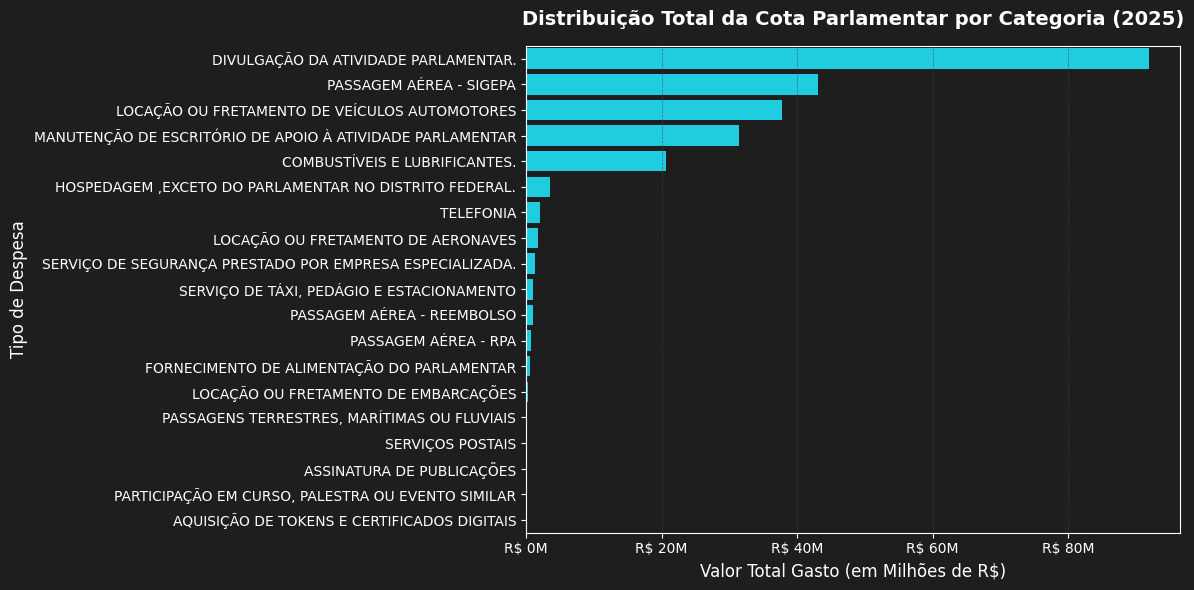

 RELATÓRIO DE ALOCAÇÃO DE RECURSOS - COTA PARLAMENTAR
A categoria 'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.' concentra sozinha R$ 91.9M (38.7% do total gasto em 2025).
As 3 maiores categorias somadas ('DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.', 'PASSAGEM AÉREA - SIGEPA' e 'LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES') respondem 
 por 72.7% de toda a Cota Parlamentar.
Isso sugere que a fiscalização orçamentária pode ser mais eficiente se concentrada nessas poucas categorias, em vez de pulverizada.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# 1. Limpa qualquer configuração travada
plt.rcParams.update(plt.rcParamsDefault)

# 2. Força o fundo escuro moderno
plt.style.use('dark_background')
plt.rcParams.update({
    'axes.facecolor': '#1e1e1e',
    'figure.facecolor': '#1e1e1e',
    'grid.color': '#444444',
    'text.color': 'white',
    'axes.labelcolor': 'white',
    'xtick.color': 'white',
    'ytick.color': 'white'
})

fig, ax = plt.subplots(figsize=(12, 6))

# 3. Força uma cor sólida e brilhante (Ciano) para não ter erro de visualização
sns.barplot(
    data=df_gastos_agrupados,
    x='Valor_Documento',
    y='Tipo_Despesa',
    color='#00e5ff',
    ax=ax
)

# Formatação
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'R$ {x/1e6:.0f}M'))
ax.set_title('Distribuição Total da Cota Parlamentar por Categoria (2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Valor Total Gasto (em Milhões de R$)', fontsize=12)
ax.set_ylabel('Tipo de Despesa', fontsize=12)
ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.show()

total_gasto = df_gastos_agrupados['Valor_Documento'].sum()
top_categoria = df_gastos_agrupados.iloc[0]
top3 = df_gastos_agrupados.head(3)
pct_top3 = top3['Valor_Documento'].sum() / total_gasto * 100

print("="*70)
print(" RELATÓRIO DE ALOCAÇÃO DE RECURSOS - COTA PARLAMENTAR")
print("="*70)
print(f"A categoria '{top_categoria['Tipo_Despesa']}' concentra sozinha "
      f"R$ {top_categoria['Valor_Documento']/1e6:.1f}M "
      f"({top_categoria['Valor_Documento']/total_gasto*100:.1f}% do total gasto em 2025).")
print(f"As 3 maiores categorias somadas ('{top3.iloc[0]['Tipo_Despesa']}', "
      f"'{top3.iloc[1]['Tipo_Despesa']}' "
      f"e '{top3.iloc[2]['Tipo_Despesa']}') "
      f"respondem \n por {pct_top3:.1f}% de toda a Cota Parlamentar.")
print("Isso sugere que a fiscalização orçamentária pode ser mais eficiente "
      "se concentrada nessas poucas categorias, em vez de pulverizada.")
print("="*70)
#  impede que o Jupyter textos
pass

###  Análise Temporal: Sazonalidade dos Gastos em 2025

Após compreendermos as categorias de despesa, é fundamental analisarmos o comportamento financeiro ao longo do tempo. O gráfico de série temporal abaixo ilustra a evolução mensal dos gastos com a Cota Parlamentar.
Esta visualização é crucial para identificar padrões de sazonalidade, como picos de gastos concentrados em períodos específicos do calendário legislativo.

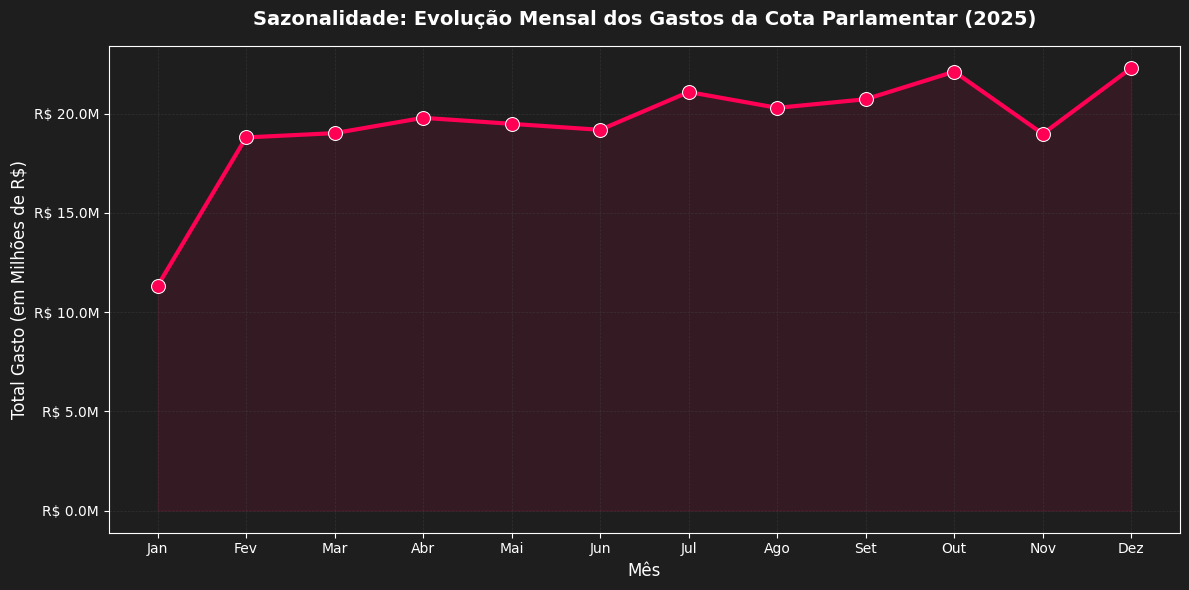

 RELATÓRIO DE SAZONALIDADE - GASTOS MENSAIS (2025)
O mês de maior gasto foi Dez, com R$ 22.3M, contra R$ 11.3M em Jan (mês mais econômico).
Variação de 97% entre o pico e o vale do ano.
Picos costumam coincidir com recesso legislativo (viagens ao estado de origem) ou períodos eleitorais, quando a divulgação parlamentar tende a subir.


In [ ]:
# ==============================================================================
# VISUALIZAÇÃO 2 : SÉRIE TEMPORAL DE GASTOS MENSAIS
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import pandas as pd
import calendar

# Configuração Dark IDE
plt.rcParams.update(plt.rcParamsDefault)
plt.style.use('dark_background')
plt.rcParams.update({
    'axes.facecolor': '#1e1e1e', 'figure.facecolor': '#1e1e1e',
    'grid.color': '#444444', 'text.color': 'white',
    'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white'
})

# 1. Tratamento de Dados de Data (Transformando string em DateTime)
df_despesas['Data'] = pd.to_datetime(df_despesas['Data'], errors='coerce')

# 2. Filtrando apenas registros de 2025 e removendo nulos
df_despesas_2025 = df_despesas[(df_despesas['Data'].dt.year == 2025) & (df_despesas['Data'].notnull())].copy()

# 3. Extraindo o mês e agregando os valores
df_despesas_2025['Mes_Num'] = df_despesas_2025['Data'].dt.month
df_sazonalidade = df_despesas_2025.groupby('Mes_Num')['Valor_Documento'].sum().reset_index()

# 4. Mapeando números para nomes curtos dos meses (Jan, Fev, Mar...)
meses_pt = {1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
            7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'}
df_sazonalidade['Mes_Nome'] = df_sazonalidade['Mes_Num'].map(meses_pt)

# Plotagem
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=df_sazonalidade,
    x='Mes_Nome',
    y='Valor_Documento',
    color='#ff0055', # Rosa Neon brilhante
    marker='o',      # Marcadores em cada mês
    markersize=10,
    linewidth=3,
    ax=ax
)

# Preenchendo a área debaixo da linha para um visual mais moderno
ax.fill_between(df_sazonalidade['Mes_Nome'], df_sazonalidade['Valor_Documento'], color='#ff0055', alpha=0.1)

# Formatação
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f'R$ {y/1e6:.1f}M'))
ax.set_title('Sazonalidade: Evolução Mensal dos Gastos da Cota Parlamentar (2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Mês', fontsize=12)
ax.set_ylabel('Total Gasto (em Milhões de R$)', fontsize=12)
ax.grid(linestyle='--', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()

mes_pico = df_sazonalidade.loc[df_sazonalidade['Valor_Documento'].idxmax()]
mes_vale = df_sazonalidade.loc[df_sazonalidade['Valor_Documento'].idxmin()]
variacao_pct = (mes_pico['Valor_Documento'] - mes_vale['Valor_Documento']) / mes_vale['Valor_Documento'] * 100

print("="*70)
print(" RELATÓRIO DE SAZONALIDADE - GASTOS MENSAIS (2025)")
print("="*70)
print(f"O mês de maior gasto foi {mes_pico['Mes_Nome']}, com R$ {mes_pico['Valor_Documento']/1e6:.1f}M, "
      f"contra R$ {mes_vale['Valor_Documento']/1e6:.1f}M em {mes_vale['Mes_Nome']} (mês mais econômico).")
print(f"Variação de {variacao_pct:.0f}% entre o pico e o vale do ano.")
print("Picos costumam coincidir com recesso legislativo (viagens ao estado de origem) "
      "ou períodos eleitorais, quando a divulgação parlamentar tende a subir.")
print("="*70)

pass

### Análise de Produtividade Legislativa por Partido

Após compreendermos a distribuição macro dos gastos da Cota Parlamentar, a etapa seguinte da nossa análise busca mensurar a contrapartida desse investimento público: a **produtividade legislativa**.

No gráfico abaixo, agrupamos o volume total de Projetos de Lei propostos no ano e os categorizamos por partido político. O objetivo é identificar quais legendas demonstram maior tração absoluta na criação de pautas na Câmara.

*Nota Técnica de Engenharia:* Para garantir a integridade total desta volumetria, o pipeline de extração foi construído com algoritmos de paginação (*pagination*), garantindo a coleta de 100% do histórico legislativo de cada parlamentar no ano vigente, superando os limites de retorno por requisição da API governamental.

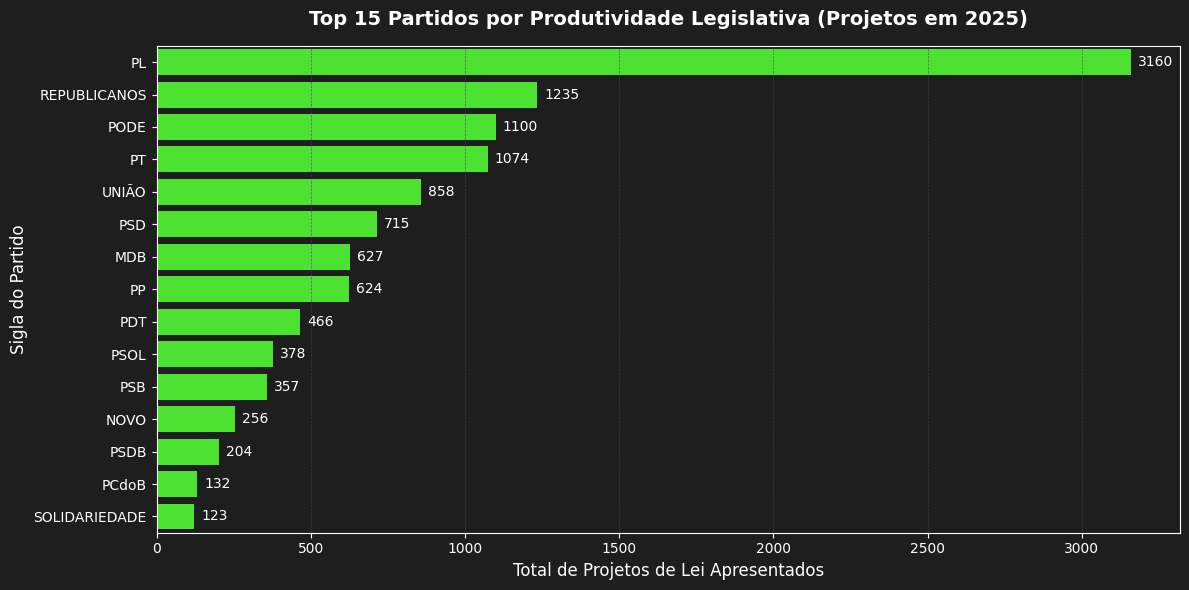

 RELATÓRIO DE PRODUTIVIDADE LEGISLATIVA POR PARTIDO
O partido 'PL' lidera com 3160 projetos, 27.0% de tudo que foi apresentado na Câmara em 2025.
Esse ranking tende a refletir o tamanho da bancada de cada partido mais do que a eficiência individual — por isso o 
próximo gráfico corrige essa distorção olhando o nível de cada deputado.


In [ ]:
# ==============================================================================
# VISUALIZAÇÃO 3: PRODUTIVIDADE LEGISLATIVA POR PARTIDO
# ==============================================================================

# 1. Preparação dos dados: Agrupando total de projetos por partido
df_produtividade = df_analise.groupby('Partido')['Total_Projetos'].sum().sort_values(ascending=False).reset_index()

# Pegando apenas os 15 partidos mais produtivos para o gráfico não ficar espremido
df_top15_produtividade = df_produtividade.head(15)

fig, ax = plt.subplots(figsize=(12, 6))

# 2. Gráfico de barras com uma cor vibrante diferente (Verde Limão/Neon)
sns.barplot(
    data=df_top15_produtividade,
    x='Total_Projetos',
    y='Partido',
    color='#39ff14',  # Verde neon para contrastar com o fundo escuro
    ax=ax
)

# 3. Formatação
ax.set_title('Top 15 Partidos por Produtividade Legislativa (Projetos em 2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Total de Projetos de Lei Apresentados', fontsize=12)
ax.set_ylabel('Sigla do Partido', fontsize=12)
ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.7)

# Adicionando os números exatos na ponta de cada barra para facilitar a leitura
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width)}',
                xy=(width, p.get_y() + p.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha='left', va='center', color='white', fontsize=10)

plt.tight_layout()
plt.show()

top_partido = df_top15_produtividade.iloc[0]
total_projetos_ano = df_produtividade['Total_Projetos'].sum()
pct_top_partido = top_partido['Total_Projetos'] / total_projetos_ano * 100

print("="*70)
print(" RELATÓRIO DE PRODUTIVIDADE LEGISLATIVA POR PARTIDO")
print("="*70)
print(f"O partido '{top_partido['Partido']}' lidera com {int(top_partido['Total_Projetos'])} projetos, "
      f"{pct_top_partido:.1f}% de tudo que foi apresentado na Câmara em 2025.")
print("Esse ranking tende a refletir o tamanho da bancada de cada partido mais do "
      "que a eficiência individual — por isso o \n"
      "próximo gráfico corrige essa distorção "
      "olhando o nível de cada deputado.")
print("="*70)
# Silencia qualquer log residual
pass

###  O Clímax Analítico: Correlação entre Gasto e Produtividade (Custo-Benefício)

O volume absoluto de projetos por partido não responde à nossa pergunta central, pois legendas maiores naturalmente produzem mais. Para uma análise 100% justa de eficiência, precisamos descer a granularidade para o **nível individual**.

O Gráfico de Dispersão (*Scatter Plot*) abaixo cruza o **Gasto Total** de cada deputado (Eixo X, com teto legal próximo a R$ 600 mil anuais) com a sua respectiva **Produtividade Legislativa** (Eixo Y).

O cruzamento das médias (linhas pontilhadas) divide a Câmara em 4 quadrantes analíticos:
* **Quadrante Superior Esquerdo:** Alta Eficiência (*Top Performers* - Alto volume de projetos com gasto abaixo da média).
* **Quadrante Inferior Direito:** Ineficiência Crítica (Alto gasto público com entrega legislativa abaixo da média).
* **Quadrante Superior Direito:** Alto impacto, alto custo.
* **Quadrante Inferior Esquerdo:** Baixo impacto, baixo custo.

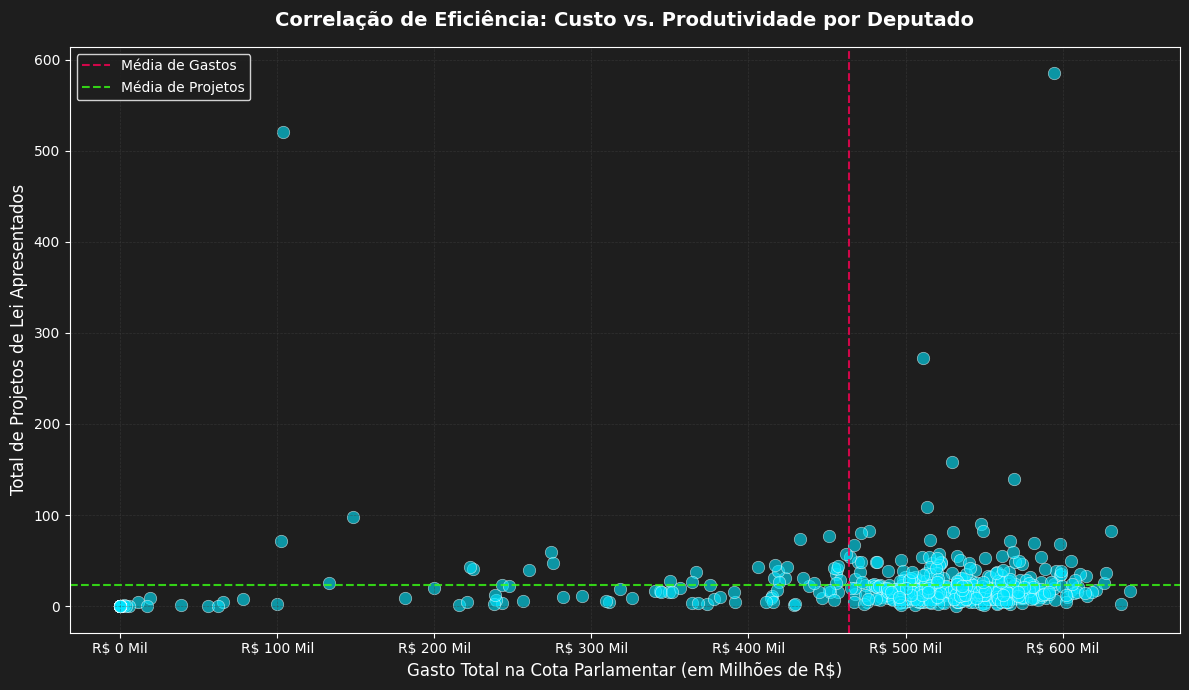

 RELATÓRIO DE EFICIÊNCIA - GASTO vs. PRODUTIVIDADE INDIVIDUAL
32 deputados estão no quadrante de Alta Eficiência (gasto abaixo da média de R$ 464 mil e produtividade acima da média de 22.9 projetos).
Destaque: Amom Mandel (REPUBLICANOS/AM) apresentou 521 projetos gastando apenas R$ 104 mil.
Já 262 deputados estão em Ineficiência Crítica (gasto acima da média com produtividade abaixo da média).
Caso mais extremo: Helena Lima (PSD/RR) gastou R$ 643 mil apresentando apenas 17 projeto(s).
----------------------------------------------------------------------
RANKING POR CUSTO-BENEFÍCIO INDIVIDUAL (Custo_por_Projeto)
----------------------------------------------------------------------
Mais custo-eficiente: Amom Mandel (REPUBLICANOS/AM) — R$ 200 por projeto apresentado.
Menos custo-eficiente (entre quem apresentou ao menos 1 projeto): Marcos Aurélio Sampaio (MDB/PI) — R$ 549841 por projeto.
Nota: esta métrica é uma proxy (gasto total da Cota ÷ número de PLs), não um custo de produção real 

In [ ]:
# ==============================================================================
# VISUALIZAÇÃO 4: CORRELAÇÃO GASTO VS PRODUTIVIDADE (SCATTER PLOT)
# ==============================================================================

# Configuração Dark IDE
plt.rcParams.update(plt.rcParamsDefault)
plt.style.use('dark_background')
plt.rcParams.update({
    'axes.facecolor': '#1e1e1e', 'figure.facecolor': '#1e1e1e',
    'grid.color': '#444444', 'text.color': 'white',
    'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white'
})

fig, ax = plt.subplots(figsize=(12, 7))

# Gráfico de dispersão (Scatter Plot)
# Cada 'ponto' é um deputado
sns.scatterplot(
    data=df_analise,
    x='Gasto_Total_R$',
    y='Total_Projetos',
    color='#00e5ff', # Ciano brilhante para contraste
    alpha=0.6,       # Transparência para vermos pontos sobrepostos
    s=80,            # Tamanho do ponto
    edgecolor='white',
    linewidth=0.5,
    ax=ax
)

# Formatação dos Eixos
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'R$ {x/1e3:.0f} Mil'))
ax.set_title('Correlação de Eficiência: Custo vs. Produtividade por Deputado', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Gasto Total na Cota Parlamentar (em Milhões de R$)', fontsize=12)
ax.set_ylabel('Total de Projetos de Lei Apresentados', fontsize=12)

# Adicionando linhas de média para criar quadrantes visuais de análise
media_gasto = df_analise['Gasto_Total_R$'].mean()
media_projetos = df_analise['Total_Projetos'].mean()

ax.axvline(media_gasto, color='#ff0055', linestyle='--', linewidth=1.5, alpha=0.8, label='Média de Gastos')
ax.axhline(media_projetos, color='#39ff14', linestyle='--', linewidth=1.5, alpha=0.8, label='Média de Projetos')

ax.legend(facecolor='#1e1e1e', edgecolor='white')
ax.grid(linestyle='--', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()

df_top_performers = df_analise[
    (df_analise['Gasto_Total_R$'] < media_gasto) &
    (df_analise['Total_Projetos'] > media_projetos)
].sort_values('Total_Projetos', ascending=False)

df_ineficientes = df_analise[
    (df_analise['Gasto_Total_R$'] > media_gasto) &
    (df_analise['Total_Projetos'] < media_projetos)
].sort_values('Gasto_Total_R$', ascending=False)

n_top = len(df_top_performers)
n_inef = len(df_ineficientes)

print("="*70)
print(" RELATÓRIO DE EFICIÊNCIA - GASTO vs. PRODUTIVIDADE INDIVIDUAL")
print("="*70)
print(f"{n_top} deputados estão no quadrante de Alta Eficiência (gasto abaixo da média "
      f"de R$ {media_gasto/1e3:.0f} mil e produtividade acima da média de {media_projetos:.1f} projetos).")
if n_top > 0:
    exemplo = df_top_performers.iloc[0]
    print(f"Destaque: {exemplo['Nome']} ({exemplo['Partido']}/{exemplo['UF']}) apresentou "
          f"{int(exemplo['Total_Projetos'])} projetos gastando apenas R$ {exemplo['Gasto_Total_R$']/1e3:.0f} mil.")
print(f"Já {n_inef} deputados estão em Ineficiência Crítica "
      "(gasto acima da média com produtividade abaixo da média).")
if n_inef > 0:
    pior = df_ineficientes.iloc[0]
    print(f"Caso mais extremo: {pior['Nome']} ({pior['Partido']}/{pior['UF']}) gastou "
          f"R$ {pior['Gasto_Total_R$']/1e3:.0f} mil apresentando apenas {int(pior['Total_Projetos'])} projeto(s).")
print("="*70)

# Ranking por Custo_por_Projeto (métrica individual, ignorando quem tem 0 projetos)
df_ranking_eficiencia = df_analise[df_analise['Total_Projetos'] > 0].sort_values('Custo_por_Projeto')

mais_eficiente = df_ranking_eficiencia.iloc[0]
menos_eficiente = df_ranking_eficiencia.iloc[-1]

print("-"*70)
print("RANKING POR CUSTO-BENEFÍCIO INDIVIDUAL (Custo_por_Projeto)")
print("-"*70)
print(f"Mais custo-eficiente: {mais_eficiente['Nome']} ({mais_eficiente['Partido']}/{mais_eficiente['UF']}) — "
      f"R$ {mais_eficiente['Custo_por_Projeto']:.0f} por projeto apresentado.")
print(f"Menos custo-eficiente (entre quem apresentou ao menos 1 projeto): "
      f"{menos_eficiente['Nome']} ({menos_eficiente['Partido']}/{menos_eficiente['UF']}) — "
      f"R$ {menos_eficiente['Custo_por_Projeto']:.0f} por projeto.")
print("Nota: esta métrica é uma proxy (gasto total da Cota ÷ número de PLs), não um custo "
      "de produção real por projeto, já que as despesas não são vinculadas a proposições específicas.")
print("="*70)
pass

In [ ]:
print("="*70)
print(" CONCLUSÃO GERAL DA ANÁLISE")
print("="*70)
print(f"1. Alocação de Recursos: a Cota Parlamentar é fortemente concentrada — "
      f"'{top_categoria['Tipo_Despesa']}' sozinha consome "
      f"{top_categoria['Valor_Documento']/total_gasto*100:.1f}% do total gasto.")
print(f"2. Sazonalidade: os gastos não são uniformes ao longo do ano; "
      f"{mes_pico['Mes_Nome']} concentra o pico de despesas, sugerindo relação "
      "com o calendário legislativo/eleitoral.")
print(f"3. Produtividade por Partido: o ranking é dominado por '{top_partido['Partido']}', "
      "mas isso reflete principalmente o tamanho da bancada, não eficiência.")
print(f"4. Eficiência Individual: ao corrigir por deputado, identificamos "
      f"{n_top} 'Top Performers' (baixo custo, alta produtividade) \n— com destaque "
      f"para {df_top_performers.iloc[0]['Nome'] if n_top else 'N/A'} — "
      f"e {n_inef} casos de Ineficiência Crítica.")
print("-"*70)
print("Em suma: o gasto público na Cota Parlamentar não se correlaciona diretamente "
      "com produtividade legislativa. A eficiência real só aparece quando se olha "
      "o indivíduo, não \no partido ou o volume absoluto de projetos.")
print("="*70)

 CONCLUSÃO GERAL DA ANÁLISE
1. Alocação de Recursos: a Cota Parlamentar é fortemente concentrada — 'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.' sozinha consome 38.7% do total gasto.
2. Sazonalidade: os gastos não são uniformes ao longo do ano; Dez concentra o pico de despesas, sugerindo relação com o calendário legislativo/eleitoral.
3. Produtividade por Partido: o ranking é dominado por 'PL', mas isso reflete principalmente o tamanho da bancada, não eficiência.
4. Eficiência Individual: ao corrigir por deputado, identificamos 32 'Top Performers' (baixo custo, alta produtividade) 
— com destaque para Amom Mandel — e 262 casos de Ineficiência Crítica.
----------------------------------------------------------------------
Em suma: o gasto público na Cota Parlamentar não se correlaciona diretamente com produtividade legislativa. A eficiência real só aparece quando se olha o indivíduo, não 
o partido ou o volume absoluto de projetos.


tentativa de rodar algoritmo de Ml


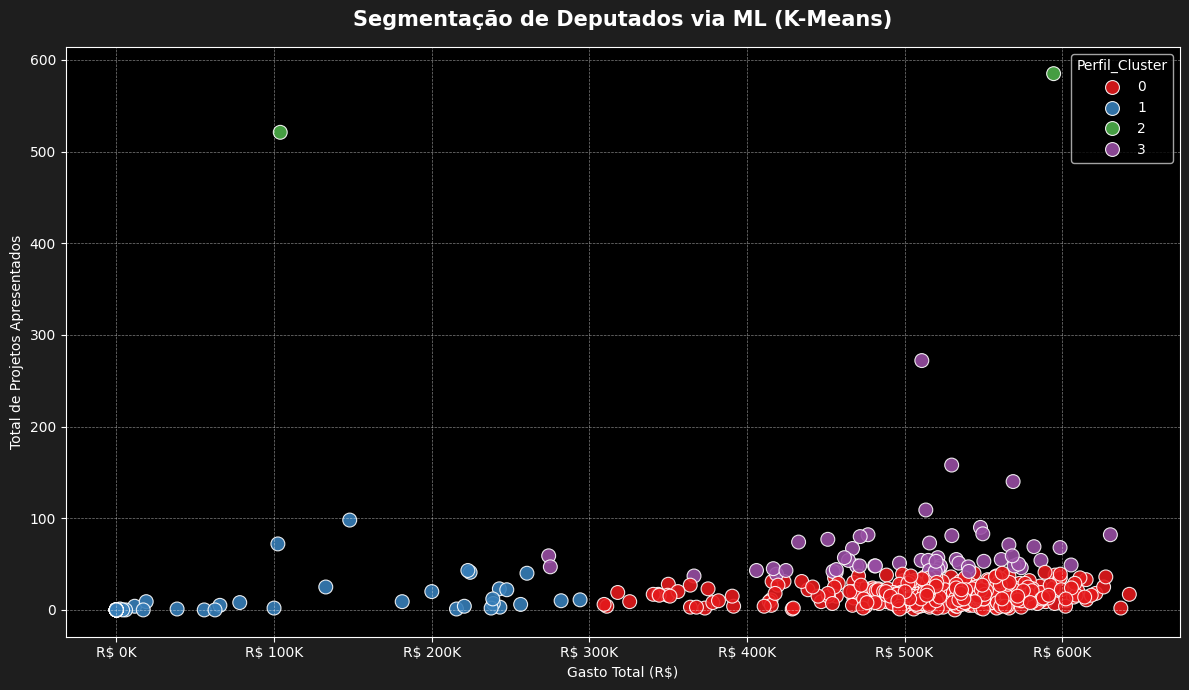

,Gasto_Total_R$,Total_Projetos,Custo_por_Projeto
Perfil_Cluster,,,
0,521590.57,16.76,52260.11
1,73879.91,7.60,12998.59
2,349282.53,553.00,607.98
3,502552.23,63.73,8972.71


In [ ]:
# Importando as bibliotecas de Machine Learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Selecionando as variáveis que vão definir os perfis
features = df_analise[['Gasto_Total_R$', 'Total_Projetos']]

# 2. Padronizando os dados (para Gasto e Projetos terem o mesmo peso)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# 3. Criando o "Cérebro" do algoritmo (vamos pedir 4 grupos)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# 4. Treinando o modelo e já salvando o resultado numa nova coluna
# Ele vai classificar cada deputado com um número: 0, 1, 2 ou 3.
df_analise['Perfil_Cluster'] = kmeans.fit_predict(features_scaled)

# ==========================================
# VISUALIZAÇÃO DOS RESULTADOS
# ==========================================
# Vamos plotar para ver como a IA dividiu os deputados
plt.figure(figsize=(12, 7))

# Mantendo o estilo escuro que você usou no seu projeto
plt.style.use('dark_background')

sns.scatterplot(
    data=df_analise,
    x='Gasto_Total_R$',
    y='Total_Projetos',
    hue='Perfil_Cluster',
    palette='Set1', # Paleta de cores bem distinta
    s=100,
    alpha=0.9
)

plt.title('Segmentação de Deputados via ML (K-Means)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Gasto Total (R$)')
plt.ylabel('Total de Projetos Apresentados')

# Formatando o eixo X para milhões (como você fez no Ato 3)
from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'R$ {x/1e3:.0f}K'))

plt.grid(axis='both', linestyle='--', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# ANÁLISE: O QUE CADA CLUSTER SIGNIFICA?
# ==========================================
# Vamos calcular a média de cada grupo para entender o comportamento deles
resumo_perfis = df_analise.groupby('Perfil_Cluster')[['Gasto_Total_R$', 'Total_Projetos', 'Custo_por_Projeto']].mean().round(2)
display(resumo_perfis)

## Sugestões para Trabalhos Futuros

### 1. ~~Paralelização da Extração~~ ✅ Implementado
O pipeline de extração inicialmente executava requisições sequenciais para
aproximadamente 513 deputados. Foi refatorado com `concurrent.futures.ThreadPoolExecutor`
(8 workers), reduzindo o tempo total de extração de aproximadamente 20 minutos para
5.3 minutos (aproximadamente 4x de ganho), sem alterar a lógica de negócio do pipeline.

### 2. Segmentação de Deputados via Clustering (KMeans)
Hoje a análise de eficiência (Ato 3) usa a média de gasto/produtividade como corte fixo
para os quadrantes. Uma extensão natural seria aplicar `KMeans` sobre as variáveis
`Gasto_Total_R$` e `Total_Projetos` para segmentar os deputados em perfis de comportamento
de forma não supervisionada, em vez de usar um corte arbitrário pela média.

### 3. Análise de Texto sobre as Ementas das Proposições (NLP)
A API da Câmara já classifica proposições por tema oficial (`/proposicoes/{id}/temas`),
então replicar essa classificação via ML seria redundante. Uma direção mais interessante
seria aplicar NLP sobre o texto da ementa (campo `Tema` já coletado) para agrupamento
temático mais granular ou análise de tom/complexidade textual — algo que a API não entrega hoje.